# RiceFlow — Machine Learning Model Training & Validation

**Models documented in this notebook:**
1. **K-Means Clustering** — groups rice varieties by agro-climatic similarity (supplementary metadata attached to variety recommendations).
2. **Linear Regression** — predicts expected rice yield (t/ha) from farm, soil, and climate conditions.

This notebook mirrors the exact training code used in the RiceFlow Django backend
(`apps/recommendations/clustering.py` and `apps/predictions/services.py`), so
every metric produced here matches what the deployed system computes. It is
intended as the reproducible model-training appendix for the thesis manuscript.

**Reproducibility.** All stochastic steps (`KMeans`, `train_test_split`,
synthetic-data generation) use a fixed `random_state=42`, so re-running this
notebook top-to-bottom reproduces identical numbers.


In [1]:
import os
import warnings

# Keep the appendix output clean: pin joblib's worker count (Windows core
# detection emits a noisy warning otherwise) and silence non-actionable warnings.
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '4')
warnings.filterwarnings('ignore')

import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

print(f"Python      : {platform.python_version()}")
print(f"numpy       : {np.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


Python      : 3.13.13
numpy       : 2.1.3
pandas      : 2.2.3
scikit-learn: 1.5.2
matplotlib  : 3.11.1


---
# Part 1 — K-Means Clustering of Rice Varieties

## 1.1 Methodology

**Why K-Means.** K-Means is used to group the varieties in RiceFlow's catalog
into agro-climatically similar clusters. The cluster label is stored as
*supplementary metadata* on a recommendation result — it does not itself rank
varieties (ranking is produced separately by a weighted Rice Suitability
Index). K-Means was chosen over hierarchical or density-based clustering
because: the variety catalog is small and unlabeled, the desired output is a
flat partition rather than a dendrogram, and K-Means centroids are cheap to
persist and reuse at inference time (`scaler.pkl` + `kmeans.pkl`, loaded once
per prediction).

**Feature selection.** Each variety is represented as a 9-dimensional vector
covering the traits that actually differentiate where and how a variety
performs: ecosystem, three stress-tolerance ratings (submergence, drought,
salinity), average yield potential, maturity duration, its optimal
temperature band, and its minimum rainfall requirement. Categorical traits
(ecosystem, tolerance levels) are ordinally encoded; all 9 columns are then
standardized (zero mean, unit variance) with `StandardScaler` so that
yield (t/ha, small numbers) does not get swamped by rainfall (mm, large
numbers) purely due to scale.

**Choosing k.** Rather than picking a cluster count by inspection, k is swept
over `[2, 8]` (capped at `n_samples - 1`) and the k that **maximizes the
silhouette score** is kept. Silhouette score measures how well-separated and
internally cohesive the resulting clusters are (range −1 to 1; higher is
better) and does not require ground-truth labels, which is appropriate here
since there is no external "correct" clustering to validate against. The
Davies–Bouldin index (lower is better) is reported alongside as a second,
independent measure of cluster separation.

## 1.2 Data

The dataset below is the RiceFlow reference catalog of 17 NSIC-released rice
varieties actively used by the system's recommendation engine — the same
records loaded into production via `load_seed_data.py`. Trait values (yield
potential, maturity duration, temperature/rainfall tolerances,
stress-tolerance ratings) reflect each variety's published NSIC seed-release
characteristics.


In [2]:
# ── Rice variety reference data (RiceFlow catalog, n = 17) ─────────────────
# Same records as apps/varieties/management/commands/load_seed_data.py::VARIETIES
varieties = pd.DataFrame([
    dict(variety_id='V01', name='NSIC Rc222 (Tubigan 18)',   ecosystem='irrigated_lowland', maturity_days=113, avg_yield_t_ha=5.2, submergence_tolerance='moderate', drought_tolerance='low',      salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
    dict(variety_id='V02', name='NSIC Rc160 (Tubigan 7)',    ecosystem='irrigated_lowland', maturity_days=116, avg_yield_t_ha=5.1, submergence_tolerance='low',      drought_tolerance='low',      salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
    dict(variety_id='V03', name='NSIC Rc238 (Tubigan 21)',   ecosystem='irrigated_lowland', maturity_days=109, avg_yield_t_ha=5.4, submergence_tolerance='low',      drought_tolerance='low',      salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
    dict(variety_id='V04', name='NSIC Rc216 (Tubigan 15)',   ecosystem='irrigated_lowland', maturity_days=112, avg_yield_t_ha=5.0, submergence_tolerance='low',      drought_tolerance='low',      salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
    dict(variety_id='V05', name='NSIC Rc9 (Apo)',            ecosystem='upland',            maturity_days=120, avg_yield_t_ha=3.5, submergence_tolerance='low',      drought_tolerance='high',     salinity_tolerance='low',      optimal_temp_min=18, optimal_temp_max=32, optimal_rainfall_min=1000),
    dict(variety_id='V06', name='NSIC Rc192 (Sahod Ulan 1)', ecosystem='rainfed_lowland',   maturity_days=120, avg_yield_t_ha=3.8, submergence_tolerance='high',     drought_tolerance='moderate', salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=34, optimal_rainfall_min=1400),
    dict(variety_id='V07', name='NSIC Rc194 (Sahod Ulan 2)', ecosystem='rainfed_lowland',   maturity_days=118, avg_yield_t_ha=4.0, submergence_tolerance='high',     drought_tolerance='moderate', salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=34, optimal_rainfall_min=1400),
    dict(variety_id='V08', name='NSIC Rc272 (Tubigan 25)',   ecosystem='irrigated_lowland', maturity_days=105, avg_yield_t_ha=5.6, submergence_tolerance='low',      drought_tolerance='low',      salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
    dict(variety_id='V09', name='NSIC Rc300 (Tubigan 27)',   ecosystem='irrigated_lowland', maturity_days=108, avg_yield_t_ha=5.8, submergence_tolerance='low',      drought_tolerance='low',      salinity_tolerance='moderate', optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
    dict(variety_id='V10', name='NSIC Rc480 (Tubigan 29)',   ecosystem='irrigated_lowland', maturity_days=106, avg_yield_t_ha=6.0, submergence_tolerance='low',      drought_tolerance='low',      salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
    dict(variety_id='V11', name='NSIC Rc354 (Sahod Ulan 11)',ecosystem='rainfed_lowland',   maturity_days=115, avg_yield_t_ha=4.2, submergence_tolerance='high',     drought_tolerance='high',     salinity_tolerance='low',      optimal_temp_min=21, optimal_temp_max=33, optimal_rainfall_min=1400),
    dict(variety_id='V12', name='NSIC Rc18 (Mestizo 1)',     ecosystem='upland',            maturity_days=110, avg_yield_t_ha=3.8, submergence_tolerance='low',      drought_tolerance='high',     salinity_tolerance='low',      optimal_temp_min=18, optimal_temp_max=32, optimal_rainfall_min=900),
    dict(variety_id='V13', name='NSIC Rc106 (NERICA 4)',     ecosystem='upland',            maturity_days=95,  avg_yield_t_ha=3.2, submergence_tolerance='low',      drought_tolerance='high',     salinity_tolerance='low',      optimal_temp_min=18, optimal_temp_max=32, optimal_rainfall_min=900),
    dict(variety_id='V14', name='NSIC Rc164 (Sahod Ulan 3)', ecosystem='rainfed_lowland',   maturity_days=122, avg_yield_t_ha=3.9, submergence_tolerance='moderate', drought_tolerance='low',      salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=33, optimal_rainfall_min=1500),
    dict(variety_id='V15', name='NSIC Rc436 (Tubigan 28)',   ecosystem='irrigated_lowland', maturity_days=107, avg_yield_t_ha=5.9, submergence_tolerance='low',      drought_tolerance='low',      salinity_tolerance='moderate', optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
    dict(variety_id='V16', name='NSIC Rc402 (Sahod Ulan 10)',ecosystem='rainfed_lowland',   maturity_days=119, avg_yield_t_ha=4.1, submergence_tolerance='high',     drought_tolerance='moderate', salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=34, optimal_rainfall_min=1400),
    dict(variety_id='V17', name='NSIC Rc160-2 (Tubigan 7-2)',ecosystem='irrigated_lowland', maturity_days=114, avg_yield_t_ha=5.3, submergence_tolerance='low',      drought_tolerance='low',      salinity_tolerance='low',      optimal_temp_min=22, optimal_temp_max=35, optimal_rainfall_min=1200),
], )
varieties

,variety_id,name,ecosystem,maturity_days,avg_yield_t_ha,submergence_tolerance,drought_tolerance,salinity_tolerance,optimal_temp_min,optimal_temp_max,optimal_rainfall_min
0,V01,NSIC Rc222 (Tubigan 18),irrigated_lowland,113,5.2,moderate,low,low,22,35,1200
1,V02,NSIC Rc160 (Tubigan 7),irrigated_lowland,116,5.1,low,low,low,22,35,1200
2,V03,NSIC Rc238 (Tubigan 21),irrigated_lowland,109,5.4,low,low,low,22,35,1200
3,V04,NSIC Rc216 (Tubigan 15),irrigated_lowland,112,5.0,low,low,low,22,35,1200
4,V05,NSIC Rc9 (Apo),upland,120,3.5,low,high,low,18,32,1000
5,V06,NSIC Rc192 (Sahod Ulan 1),rainfed_lowland,120,3.8,high,moderate,low,22,34,1400
6,V07,NSIC Rc194 (Sahod Ulan 2),rainfed_lowland,118,4.0,high,moderate,low,22,34,1400
7,V08,NSIC Rc272 (Tubigan 25),irrigated_lowland,105,5.6,low,low,low,22,35,1200
8,V09,NSIC Rc300 (Tubigan 27),irrigated_lowland,108,5.8,low,low,moderate,22,35,1200
9,V10,NSIC Rc480 (Tubigan 29),irrigated_lowland,106,6.0,low,low,low,22,35,1200


In [3]:
# ── Feature matrix — identical encoding to clustering.py::_build_feature_matrix ──
TOLERANCE_MAP = {'low': 0, 'moderate': 1, 'high': 2}
ECOSYSTEM_MAP = {'irrigated_lowland': 0, 'rainfed_lowland': 1, 'upland': 2}

FEATURE_NAMES = [
    'ecosystem', 'submergence_tolerance', 'drought_tolerance', 'salinity_tolerance',
    'avg_yield_t_ha', 'maturity_days', 'optimal_temp_min', 'optimal_temp_max',
    'optimal_rainfall_min_1000mm',
]

def build_feature_matrix(df):
    rows = []
    for _, v in df.iterrows():
        rows.append([
            ECOSYSTEM_MAP.get(v.ecosystem, 0),
            TOLERANCE_MAP.get(v.submergence_tolerance, 0),
            TOLERANCE_MAP.get(v.drought_tolerance, 0),
            TOLERANCE_MAP.get(v.salinity_tolerance, 0),
            v.avg_yield_t_ha,
            v.maturity_days,
            v.optimal_temp_min,
            v.optimal_temp_max,
            v.optimal_rainfall_min / 1000,
        ])
    return np.array(rows, dtype=float)

X = build_feature_matrix(varieties)
pd.DataFrame(X, columns=FEATURE_NAMES, index=varieties['variety_id'])

,ecosystem,submergence_tolerance,drought_tolerance,salinity_tolerance,avg_yield_t_ha,maturity_days,optimal_temp_min,optimal_temp_max,optimal_rainfall_min_1000mm
variety_id,,,,,,,,,
V01,0.0,1.0,0.0,0.0,5.2,113.0,22.0,35.0,1.2
V02,0.0,0.0,0.0,0.0,5.1,116.0,22.0,35.0,1.2
V03,0.0,0.0,0.0,0.0,5.4,109.0,22.0,35.0,1.2
V04,0.0,0.0,0.0,0.0,5.0,112.0,22.0,35.0,1.2
V05,2.0,0.0,2.0,0.0,3.5,120.0,18.0,32.0,1.0
V06,1.0,2.0,1.0,0.0,3.8,120.0,22.0,34.0,1.4
V07,1.0,2.0,1.0,0.0,4.0,118.0,22.0,34.0,1.4
V08,0.0,0.0,0.0,0.0,5.6,105.0,22.0,35.0,1.2
V09,0.0,0.0,0.0,1.0,5.8,108.0,22.0,35.0,1.2


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Feature matrix shape: {X_scaled.shape}")
print(f"Per-feature mean after scaling (should be ~0): {X_scaled.mean(axis=0).round(3)}")
print(f"Per-feature std  after scaling (should be  1): {X_scaled.std(axis=0).round(3)}")

Feature matrix shape: (17, 9)
Per-feature mean after scaling (should be ~0): [-0. -0.  0. -0. -0. -0.  0. -0.  0.]
Per-feature std  after scaling (should be  1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 1.3 Model selection — sweeping k

For each candidate `k`, K-Means is fit with `n_init=50` (50 random
centroid initializations, keeping the best by inertia) and `random_state=42`
for reproducibility. Silhouette score and Davies–Bouldin index are recorded
for every k so the choice of final k is transparent and auditable, not
picked by eye.


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

K_MIN, K_MAX = 2, 8
n_samples = X_scaled.shape[0]
k_hi = min(K_MAX, n_samples - 1)

search_log = []
best = None
for k in range(K_MIN, k_hi + 1):
    km = KMeans(n_clusters=k, random_state=42, n_init=50)
    labels = km.fit_predict(X_scaled)
    sil = round(float(silhouette_score(X_scaled, labels)), 4)
    dbi = round(float(davies_bouldin_score(X_scaled, labels)), 4)
    search_log.append({'k': k, 'silhouette': sil, 'davies_bouldin': dbi})
    if best is None or sil > best['silhouette']:
        best = {'model': km, 'labels': labels, 'silhouette': sil, 'davies_bouldin': dbi, 'k': k}

search_df = pd.DataFrame(search_log)
search_df

,k,silhouette,davies_bouldin
0,2,0.5010,0.6816
1,3,0.5745,0.5537
2,4,0.6566,0.4062
3,5,0.6136,0.3593
4,6,0.5653,0.3130
5,7,0.4704,0.4078
6,8,0.4828,0.3399


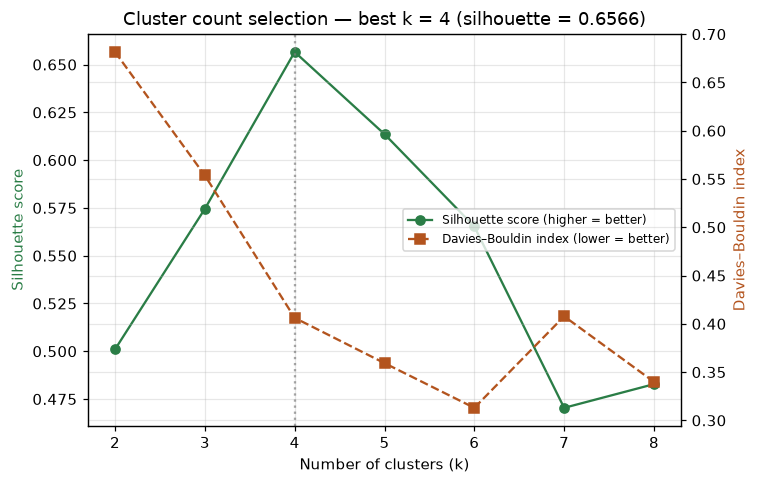

Selected k = 4  |  silhouette = 0.6566  |  Davies-Bouldin = 0.4062


In [6]:
fig, ax1 = plt.subplots(figsize=(7, 4.5))
ax2 = ax1.twinx()

ax1.plot(search_df['k'], search_df['silhouette'], 'o-', color='#2a7d46', label='Silhouette score (higher = better)')
ax2.plot(search_df['k'], search_df['davies_bouldin'], 's--', color='#b3541e', label='Davies–Bouldin index (lower = better)')

ax1.axvline(best['k'], color='gray', linestyle=':', alpha=0.7)
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('Silhouette score', color='#2a7d46')
ax2.set_ylabel('Davies–Bouldin index', color='#b3541e')
ax1.set_title(f"Cluster count selection — best k = {best['k']} (silhouette = {best['silhouette']})")
ax1.set_xticks(search_df['k'])

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=8)

fig.tight_layout()
plt.savefig('kmeans_k_selection.png', bbox_inches='tight')
plt.show()

print(f"Selected k = {best['k']}  |  silhouette = {best['silhouette']}  |  Davies-Bouldin = {best['davies_bouldin']}")

## 1.4 Cluster visualization (PCA projection)

The 9-dimensional standardized feature space is projected to 2 dimensions
with PCA purely for visualization — clustering itself was performed on the
full 9-dimensional space, not on this projection.


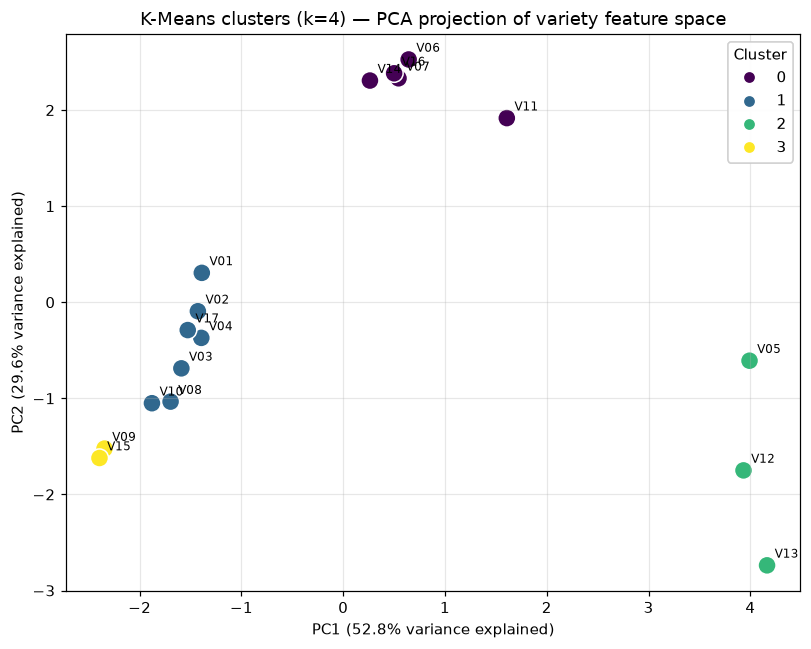

In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7.5, 6))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=best['labels'], cmap='viridis', s=140, edgecolor='white', linewidth=1)

for i, vid in enumerate(varieties['variety_id']):
    ax.annotate(vid, (X_pca[i, 0], X_pca[i, 1]), fontsize=8, xytext=(5, 5), textcoords='offset points')

ax.set_xlabel(f'PC1 ({explained[0]*100:.1f}% variance explained)')
ax.set_ylabel(f'PC2 ({explained[1]*100:.1f}% variance explained)')
ax.set_title(f'K-Means clusters (k={best["k"]}) — PCA projection of variety feature space')
legend1 = ax.legend(*scatter.legend_elements(), title='Cluster', loc='best')
ax.add_artist(legend1)

fig.tight_layout()
plt.savefig('kmeans_clusters_pca.png', bbox_inches='tight')
plt.show()

In [8]:
# ── Cluster membership and per-cluster trait profile ────────────────────────
varieties_labeled = varieties.copy()
varieties_labeled['cluster'] = best['labels']

for c in sorted(varieties_labeled['cluster'].unique()):
    members = varieties_labeled[varieties_labeled['cluster'] == c]
    print(f"Cluster {c}  (n={len(members)}):")
    for _, m in members.iterrows():
        print(f"   {m.variety_id}  {m['name']:32s}  {m.ecosystem:18s}  yield={m.avg_yield_t_ha} t/ha  maturity={m.maturity_days}d")
    print()

cluster_profile = varieties_labeled.groupby('cluster')[
    ['avg_yield_t_ha', 'maturity_days', 'optimal_temp_min', 'optimal_temp_max', 'optimal_rainfall_min']
].mean().round(2)
cluster_profile

Cluster 0  (n=5):
   V06  NSIC Rc192 (Sahod Ulan 1)         rainfed_lowland     yield=3.8 t/ha  maturity=120d
   V07  NSIC Rc194 (Sahod Ulan 2)         rainfed_lowland     yield=4.0 t/ha  maturity=118d
   V11  NSIC Rc354 (Sahod Ulan 11)        rainfed_lowland     yield=4.2 t/ha  maturity=115d
   V14  NSIC Rc164 (Sahod Ulan 3)         rainfed_lowland     yield=3.9 t/ha  maturity=122d
   V16  NSIC Rc402 (Sahod Ulan 10)        rainfed_lowland     yield=4.1 t/ha  maturity=119d

Cluster 1  (n=7):
   V01  NSIC Rc222 (Tubigan 18)           irrigated_lowland   yield=5.2 t/ha  maturity=113d
   V02  NSIC Rc160 (Tubigan 7)            irrigated_lowland   yield=5.1 t/ha  maturity=116d
   V03  NSIC Rc238 (Tubigan 21)           irrigated_lowland   yield=5.4 t/ha  maturity=109d
   V04  NSIC Rc216 (Tubigan 15)           irrigated_lowland   yield=5.0 t/ha  maturity=112d
   V08  NSIC Rc272 (Tubigan 25)           irrigated_lowland   yield=5.6 t/ha  maturity=105d
   V10  NSIC Rc480 (Tubigan 29)           i

,avg_yield_t_ha,maturity_days,optimal_temp_min,optimal_temp_max,optimal_rainfall_min
cluster,,,,,
0,4.00,118.80,21.8,33.6,1420.00
1,5.37,110.71,22.0,35.0,1200.00
2,3.50,108.33,18.0,32.0,933.33
3,5.85,107.50,22.0,35.0,1200.00


**Interpretation.** Clusters separate primarily along ecosystem and
stress-tolerance lines — e.g. high-yield irrigated-lowland varieties with low
stress tolerance group together and are distinct from rainfed varieties
carrying submergence tolerance (Sub1 gene lines) and from upland,
drought-tolerant varieties. This matches known rice agronomy: irrigated,
rainfed-lowland, and upland ecosystems demand different variety traits, and
K-Means recovers that structure from the trait data alone (it is never told
the ecosystem label directly influences yield — the encoded ecosystem column
is only one of 9 inputs).

## 1.5 Persisting the model

The fitted scaler and K-Means model are the same two artifacts loaded at
inference time by `predict_cluster()` / `get_farm_cluster()` in
`apps/recommendations/clustering.py`.


In [9]:
import joblib
from pathlib import Path

ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)

joblib.dump(scaler, ARTIFACT_DIR / 'scaler.pkl')
joblib.dump(best['model'], ARTIFACT_DIR / 'kmeans.pkl')
print(f"Saved: {ARTIFACT_DIR / 'scaler.pkl'}")
print(f"Saved: {ARTIFACT_DIR / 'kmeans.pkl'}")

Saved: artifacts\scaler.pkl
Saved: artifacts\kmeans.pkl


## 1.6 Limitations

- The catalog currently has 17 varieties; cluster stability should be
  re-evaluated as more varieties are added to the system.
- K-Means assumes roughly spherical, similarly-sized clusters in the scaled
  feature space; if future traits introduce strongly non-convex groupings, a
  density-based method (e.g. DBSCAN) may fit better.
- Cluster labels are supplementary metadata only — the actual
  variety-to-farm ranking in RiceFlow is computed by a separate, deterministic
  Rice Suitability Index, not by cluster membership.


---
# Part 2 — Linear Regression Yield Prediction

## 2.1 Methodology

**Why Linear Regression.** RiceFlow's yield estimator is used as a
decision-support figure shown to farmers and extension staff, so
interpretability is prioritized: every input's contribution to the predicted
yield can be read directly off its fitted coefficient. A more flexible
model (random forest, gradient boosting) could fit the training data more
closely, but at this stage — with model inputs and thresholds themselves
derived from literature rather than a large labeled farm dataset — a
transparent linear model is the more defensible baseline, and it is the
model actually deployed in `apps/predictions/services.py`.

**Capturing non-linear agronomy with a linear model.** Rice yield does not
respond linearly to soil pH, heat, or rainfall — yield peaks at an optimum pH
and *declines* on either side of it, heat stress only bites above a
sterility threshold, and both drought and waterlogging separately cut yield
in opposite directions. A plain linear model cannot express any of that. The
fix used here is **feature engineering**: six additional columns are
computed from the raw inputs so that the *engineered* columns are what
enters the (still linear) model, while jointly they encode the known
non-linear relationships:

| Engineered feature | Formula | Captures |
|---|---|---|
| `ph_stress` | (pH − 6.2)² | distance from the pH optimum (rice grows best near pH 6.2) |
| `heat_stress` | max(0, temp − 33) | spikelet sterility risk once flowering temperature exceeds ~33 °C |
| `rain_deficit` | max(0, 1400 − rainfall) / 1000 | water-limited / drought conditions below ~1400 mm |
| `rain_excess` | max(0, rainfall − 2600) / 1000 | waterlogging / flood loss above ~2600 mm |
| `flood_x_rain` | flood_risk_encoded × rain_excess | flood-prone fields suffer disproportionately more from excess rain |
| `ph_x_om` | pH × organic matter | nutrient-availability interaction |

These thresholds (pH 6.2 optimum, ~33 °C heat-sterility onset, ~1400–2600 mm
adequate rainfall band) follow documented rice agronomy guidance (IRRI Rice
Knowledge Bank / PhilRice production guides), not arbitrary tuning.

## 2.2 Data source — real vs. synthetic

RiceFlow's production code (`_get_real_training_data()`) always prefers real,
farmer-submitted `YieldRecord` rows once at least **30** exist for a given
farm/cycle. **Panabo City does not yet have 30 real yield records** in the
system — the app has been in active use for a limited time — so, exactly as
the deployed backend does, this notebook falls back to a **synthetic
training set generated from the documented agronomic relationships above**,
with realistic noise added. This is stated explicitly here rather than
disguised: the dataset below is a literature-grounded simulation used as an
interim baseline until sufficient real farm data accumulates, at which point
retraining on real records is a drop-in replacement (same feature pipeline,
same code path).


In [10]:
RAW_FEATURES = [
    'area_ha', 'soil_ph', 'organic_matter', 'avg_temperature',
    'seasonal_rainfall', 'humidity', 'elevation_m',
    'flood_risk_enc', 'ecosystem_enc', 'maturity_days', 'variety_avg_yield',
]
ENGINEERED_FEATURES = [
    'ph_stress', 'heat_stress', 'rain_deficit', 'rain_excess', 'flood_x_rain', 'ph_x_om',
]
FEATURE_NAMES_LR = RAW_FEATURES + ENGINEERED_FEATURES

PH_OPTIMUM     = 6.2
HEAT_THRESHOLD = 33.0
RAIN_LOW       = 1400.0
RAIN_HIGH      = 2600.0

def engineer_features(X_raw: np.ndarray) -> np.ndarray:
    '''Must stay identical between training and prediction (mirrors services.py).'''
    ph, om, temp, rain, flood_enc = X_raw[:, 1], X_raw[:, 2], X_raw[:, 3], X_raw[:, 4], X_raw[:, 7]

    ph_stress    = (ph - PH_OPTIMUM) ** 2
    heat_stress  = np.maximum(0.0, temp - HEAT_THRESHOLD)
    rain_deficit = np.maximum(0.0, RAIN_LOW - rain) / 1000.0
    rain_excess  = np.maximum(0.0, rain - RAIN_HIGH) / 1000.0
    flood_x_rain = flood_enc * rain_excess
    ph_x_om      = ph * om

    return np.column_stack([X_raw, ph_stress, heat_stress, rain_deficit, rain_excess, flood_x_rain, ph_x_om])


def generate_training_data(n_samples: int = 5000):
    '''Synthetic dataset following documented rice-agronomy relationships
    (identical formulation to apps/predictions/services.py::_generate_training_data).'''
    rng = np.random.default_rng(42)

    area_ha        = rng.uniform(0.5, 5.0,   n_samples)
    soil_ph        = rng.uniform(4.5, 8.0,   n_samples)
    organic_matter = rng.uniform(0.5, 4.0,   n_samples)
    avg_temp       = rng.uniform(24, 36,     n_samples)
    rainfall       = rng.uniform(800, 3500,  n_samples)
    humidity       = rng.uniform(60, 90,     n_samples)
    elevation_m    = rng.uniform(0, 600,     n_samples)
    flood_risk_enc = rng.integers(0, 3,      n_samples).astype(float)
    ecosystem_enc  = rng.integers(0, 2,      n_samples).astype(float)
    maturity_days  = rng.uniform(100, 130,   n_samples)
    variety_avg_y  = rng.uniform(4.0, 7.5,   n_samples)

    ph_stress    = (soil_ph - PH_OPTIMUM) ** 2
    heat_stress  = np.maximum(0.0, avg_temp - HEAT_THRESHOLD)
    rain_deficit = np.maximum(0.0, RAIN_LOW - rainfall) / 1000.0
    rain_excess  = np.maximum(0.0, rainfall - RAIN_HIGH) / 1000.0

    yield_t_ha = (
        variety_avg_y * 0.55
        + 1.2 * np.exp(-ph_stress / 0.9)
        + 0.22 * organic_matter
        - 1.5 * rain_deficit
        - 0.5 * rain_excess
        - 0.35 * flood_risk_enc * rain_excess
        - 0.10 * heat_stress ** 1.5
        + 0.20 * (1 - ecosystem_enc)
        - 0.15 * flood_risk_enc
        - elevation_m / 2500.0
        + rng.normal(0, 0.35, n_samples)
    )
    yield_t_ha = np.clip(yield_t_ha, 1.5, 9.5)

    X = np.column_stack([
        area_ha, soil_ph, organic_matter, avg_temp, rainfall, humidity,
        elevation_m, flood_risk_enc, ecosystem_enc, maturity_days, variety_avg_y,
    ])
    return X, yield_t_ha

X_raw, y = generate_training_data(n_samples=5000)
X_lr = engineer_features(X_raw)

print(f"Raw features:       {X_raw.shape}")
print(f"With engineered:    {X_lr.shape}  ({len(FEATURE_NAMES_LR)} columns)")
print(f"Yield range: {y.min():.2f} - {y.max():.2f} t/ha  (mean {y.mean():.2f})")

train_df = pd.DataFrame(X_lr, columns=FEATURE_NAMES_LR)
train_df['yield_t_ha'] = y
train_df.describe().round(2)

Raw features:       (5000, 11)
With engineered:    (5000, 17)  (17 columns)
Yield range: 1.50 - 6.82 t/ha  (mean 3.77)


,area_ha,soil_ph,organic_matter,avg_temperature,seasonal_rainfall,humidity,elevation_m,flood_risk_enc,ecosystem_enc,maturity_days,variety_avg_yield,ph_stress,heat_stress,rain_deficit,rain_excess,flood_x_rain,ph_x_om,yield_t_ha
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,2.73,6.25,2.26,30.05,2150.58,75.14,297.73,1.00,0.51,115.01,5.75,1.02,0.39,0.07,0.15,0.15,14.09,3.77
std,1.30,1.01,1.00,3.50,781.52,8.63,172.88,0.82,0.50,8.70,1.00,0.92,0.80,0.15,0.26,0.36,6.74,0.87
min,0.50,4.50,0.50,24.00,800.46,60.00,0.09,0.00,0.00,100.02,4.00,0.00,0.00,0.00,0.00,0.00,2.32,1.50
25%,1.60,5.37,1.37,27.00,1475.62,67.67,144.02,0.00,0.00,107.56,4.89,0.19,0.00,0.00,0.00,0.00,8.39,3.16
50%,2.71,6.27,2.27,30.12,2148.64,75.08,299.40,1.00,1.00,115.10,5.76,0.74,0.00,0.00,0.00,0.00,13.72,3.78
75%,3.87,7.10,3.12,33.07,2844.83,82.71,444.72,2.00,1.00,122.55,6.61,1.70,0.07,0.00,0.24,0.00,19.10,4.38
max,5.00,8.00,4.00,35.99,3499.95,90.00,599.87,2.00,1.00,130.00,7.50,3.24,2.99,0.60,0.90,1.80,31.69,6.82


## 2.3 Exploratory check — feature/yield relationships

Sanity-checking that the engineered features correlate with yield in the
expected direction before fitting anything.


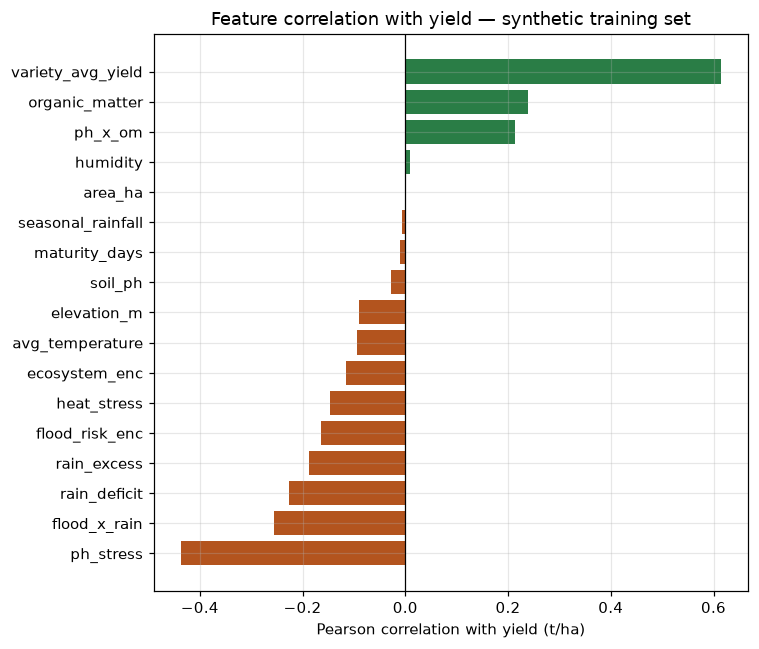

In [11]:
corr = train_df.corr(numeric_only=True)['yield_t_ha'].drop('yield_t_ha').sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
colors = ['#b3541e' if v < 0 else '#2a7d46' for v in corr.values]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson correlation with yield (t/ha)')
ax.set_title('Feature correlation with yield — synthetic training set')
fig.tight_layout()
plt.savefig('lr_feature_correlation.png', bbox_inches='tight')
plt.show()

As expected from the generating formulas: `rain_deficit`, `rain_excess`,
`heat_stress`, `ph_stress`, and `flood_risk_enc` all correlate *negatively*
with yield (they represent stress), while `variety_avg_yield` and
`organic_matter` correlate *positively*. This confirms the engineered
features carry the intended signal before any model fitting happens.

## 2.4 Train/test split and cross-validation

An 80/20 train/test split is used, with 5-fold cross-validation run on the
training split only, to get a stability estimate (mean ± std of R²) rather
than relying on a single lucky split.


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler as StandardScaler_LR
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X_train, X_test, y_train, y_test = train_test_split(X_lr, y, test_size=0.2, random_state=42)

pipe = Pipeline([('scaler', StandardScaler_LR()), ('model', LinearRegression())])

cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2')
print(f"5-fold CV R^2 scores: {np.round(cv_scores, 4)}")
print(f"5-fold CV R^2: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\nHeld-out test set (n={len(y_test)}):")
print(f"  R^2   = {r2:.4f}")
print(f"  MAE   = {mae:.4f} t/ha")
print(f"  RMSE  = {rmse:.4f} t/ha")

5-fold CV R^2 scores: [0.8202 0.8084 0.8118 0.8415 0.8195]
5-fold CV R^2: 0.8203 +/- 0.0115

Held-out test set (n=1000):
  R^2   = 0.7863
  MAE   = 0.3107 t/ha
  RMSE  = 0.3899 t/ha


## 2.5 Prediction accuracy visualization


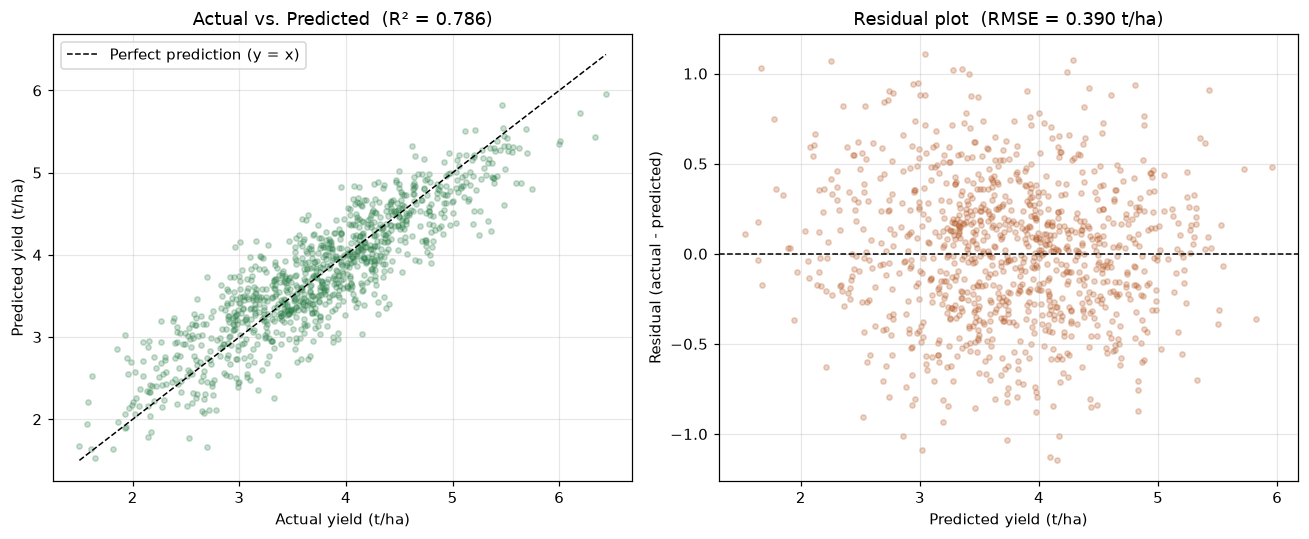

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Actual vs predicted
ax = axes[0]
ax.scatter(y_test, y_pred, alpha=0.25, s=12, color='#2a7d46')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, 'k--', linewidth=1, label='Perfect prediction (y = x)')
ax.set_xlabel('Actual yield (t/ha)')
ax.set_ylabel('Predicted yield (t/ha)')
ax.set_title(f'Actual vs. Predicted  (R² = {r2:.3f})')
ax.legend()

# Residuals
ax = axes[1]
residuals = y_test - y_pred
ax.scatter(y_pred, residuals, alpha=0.25, s=12, color='#b3541e')
ax.axhline(0, color='black', linewidth=1, linestyle='--')
ax.set_xlabel('Predicted yield (t/ha)')
ax.set_ylabel('Residual (actual - predicted)')
ax.set_title(f'Residual plot  (RMSE = {rmse:.3f} t/ha)')

fig.tight_layout()
plt.savefig('lr_prediction_accuracy.png', bbox_inches='tight')
plt.show()

## 2.6 Coefficient interpretation

Because features are standardized before fitting, each coefficient's
magnitude is directly comparable — it represents the change in predicted
yield (t/ha) per one-standard-deviation change in that feature, holding the
others fixed.


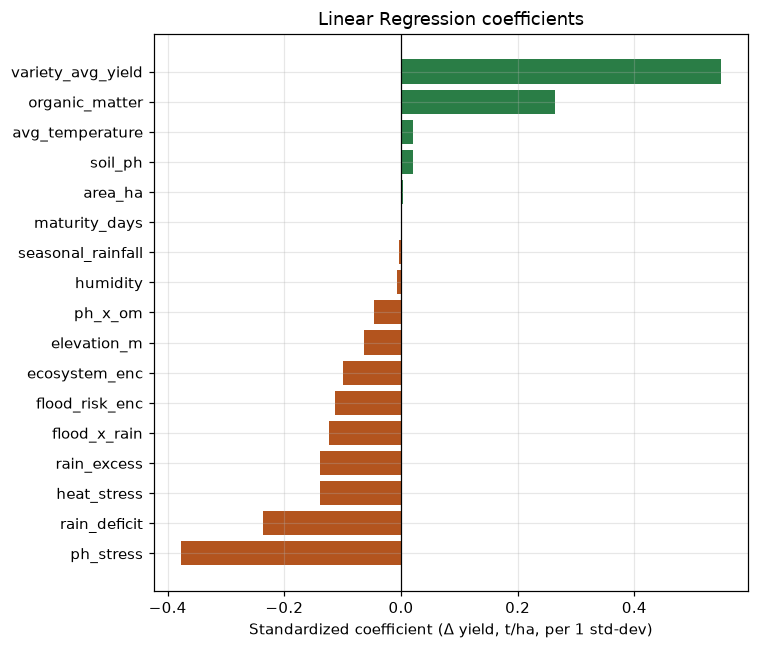

,coefficient
variety_avg_yield,0.5486
organic_matter,0.2638
avg_temperature,0.0213
soil_ph,0.0212
area_ha,0.0038
maturity_days,0.0023
seasonal_rainfall,-0.0029
humidity,-0.0067
ph_x_om,-0.0470
elevation_m,-0.0635


In [14]:
coefs = pd.Series(pipe.named_steps['model'].coef_, index=FEATURE_NAMES_LR).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
colors = ['#b3541e' if v < 0 else '#2a7d46' for v in coefs.values]
ax.barh(coefs.index, coefs.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Standardized coefficient (Δ yield, t/ha, per 1 std-dev)')
ax.set_title('Linear Regression coefficients')
fig.tight_layout()
plt.savefig('lr_coefficients.png', bbox_inches='tight')
plt.show()

coefs.sort_values(ascending=False).to_frame('coefficient').round(4)

**Interpretation.** `variety_avg_yield` and `organic_matter` carry the
largest positive coefficients — consistent with varietal yield potential and
soil fertility being the strongest yield drivers. `rain_deficit`,
`ph_stress`, and `heat_stress` carry negative coefficients of meaningful
magnitude, confirming the model has learned the intended drought, pH, and
heat-stress penalties from the engineered features rather than needing a
non-linear model to express them.

## 2.7 Persisting the model


In [15]:
joblib.dump(pipe, ARTIFACT_DIR / 'yield_linear.pkl')
print(f"Saved: {ARTIFACT_DIR / 'yield_linear.pkl'}")

summary = pd.DataFrame([{
    'model_type': 'LinearRegression (scikit-learn Pipeline: StandardScaler + LinearRegression)',
    'training_samples': len(X_train),
    'test_samples': len(X_test),
    'n_features': len(FEATURE_NAMES_LR),
    'cv_r2_mean': round(float(cv_scores.mean()), 4),
    'cv_r2_std': round(float(cv_scores.std()), 4),
    'test_r2': round(float(r2), 4),
    'test_mae_t_ha': round(float(mae), 4),
    'test_rmse_t_ha': round(float(rmse), 4),
    'data_source': 'synthetic (documented agronomic relationships) — pending >=30 real YieldRecord rows for Panabo City',
}])
summary.T.rename(columns={0: 'value'})

Saved: artifacts\yield_linear.pkl


,value
model_type,LinearRegression (scikit-learn Pipeline: Stand...
training_samples,4000
test_samples,1000
n_features,17
cv_r2_mean,0.8203
cv_r2_std,0.0115
test_r2,0.7863
test_mae_t_ha,0.3107
test_rmse_t_ha,0.3899
data_source,synthetic (documented agronomic relationships)...


## 2.8 Limitations & future work

- **Synthetic training data.** Until at least 30 real, farmer-submitted
  yield records exist for the target area (Panabo City, Davao del Norte),
  the model trains on a literature-grounded simulation rather than observed
  outcomes. The production code path (`_get_real_training_data()`) switches
  to real records automatically and transparently once that threshold is
  met — no code change is required, only data accumulation through normal
  app usage.
- **Linear model ceiling.** Even with engineered non-linear features, a
  linear model cannot capture interaction effects that were not explicitly
  engineered. If/when a larger real dataset is available, a non-linear
  model (e.g. gradient boosting) could be compared against this baseline.
- **Geographic specificity.** The agronomic thresholds used (pH 6.2 optimum,
  33 °C heat threshold, 1400–2600 mm rainfall band) are general rice-agronomy
  values, not empirically fit to Panabo City specifically — they should be
  revisited once local yield data is available.


---
# Conclusion

Two complementary models support RiceFlow's recommendation pipeline:

- **K-Means** (Part 1) groups the 17-variety catalog into agro-climatically
  coherent clusters (best k selected by silhouette score), used as
  supplementary metadata alongside the system's primary, rule-based
  suitability ranking.
- **Linear Regression** (Part 2) estimates expected yield from farm/soil/
  climate conditions, using engineered features to express known non-linear
  agronomic stress responses within an interpretable linear model, trained
  on a literature-grounded synthetic dataset pending sufficient real local
  yield records.

Both models are trained with fixed random seeds for full reproducibility,
and both persist to the same artifact format (`joblib` `.pkl`) loaded by the
deployed Django backend at inference time.
